# Using Machine Learning to Solve for RSI SMA period
Selection system: two approaches
- Create an algo that performs sentiment and fundamental analysis on crypto, giving it a score then we pick the best performers
- Identify by price action. Price movement 15m, 1hr, 4hr all positive. Then volume.

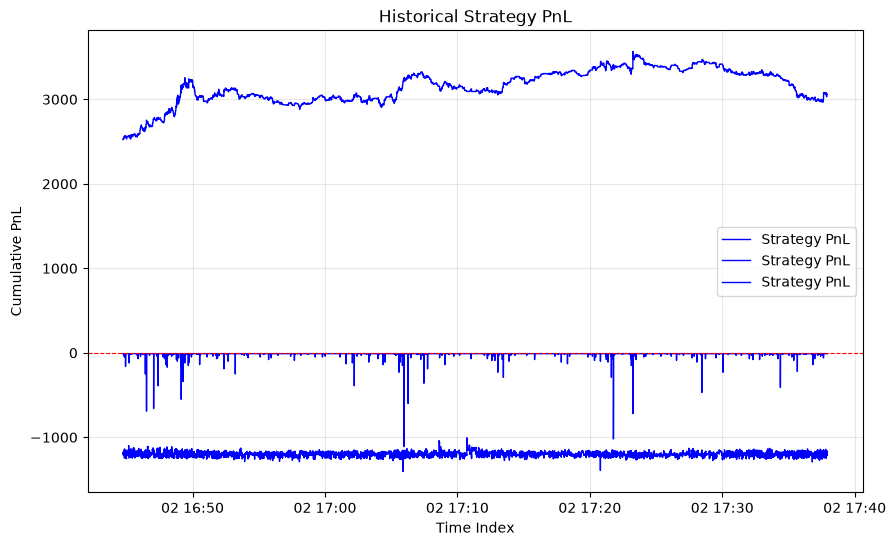

In [1]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
import numpy as np
from utils.indicators import *
from utils.engine import *

df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")
# Convert unix timestamp to datetime
df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')  # change unit to 's' if in seconds
df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

# Set datetime as index
df_orderbook = df_orderbook.set_index('datetime')
df_trades = df_trades.set_index('datetime')

# Aggregate orderbook to 1m (mid-price OHLCV style)
df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) -(df_orderbook['bid_price'] + df_orderbook['ask_price']).mean() 
df_orderbook['spread'] = (df_orderbook['bid_price'] - df_orderbook['ask_price']) * 100
df_orderbook['depth'] = (df_orderbook['bid_amount'] - df_orderbook['ask_amount']) * 4 - 1200
df_ob_1m = df_orderbook.resample('1min').agg({
    'mid_price': ['first', 'max', 'min', 'last'],
    'bid_price': 'last',
    'ask_price': 'last',
    'bid_amount': 'sum',
    'ask_amount': 'sum',
})
df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']

df_ob_1m['mid_price'] = (df_ob_1m['bid_price'] + df_ob_1m['ask_price']) / 2
df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

df_trades['buy_vol']  = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

# Aggregate trades to 1m
df_trades_1m = df_trades.resample('1min').agg({
    'price': ['first', 'max', 'min', 'last', 'count'],
    'amount': 'sum',
    'buy_vol': ['sum', 'max'],
    'sell_vol': ['sum', 'max']
})

# Flatten multi-level columns
df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume', 'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']

df_trades_1m = df_trades_1m.dropna(subset=['close'])

df_price_1m = pd.DataFrame({
    'open': df_ob_1m['open'],
    'high': df_ob_1m['high'],
    'low': df_ob_1m['low'],
    'close': df_ob_1m['close'],
    'largest_buyer': df_trades_1m['largest_buyer'] * 100 / df_trades_1m['volume'],
    'largest_seller': df_trades_1m['largest_seller'] * 100 / df_trades_1m['volume'],
    'OFI_LOB': 100*(df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount']),
    'OFI_AGG': 100*(df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller']),
    'CVD': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
    'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / abs(df_ob_1m['high'] - df_ob_1m['low']),
    'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / (df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean(),
})

plot_one(df_orderbook[['mid_price', 'spread', 'depth']].tail(80000))

# Extracting Target Variable and Advanced Data Manipulation

In [2]:
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# 1. Calculate the indicators
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
diffs = np.diff(price_clean)

# 2. Get the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)

# 3. Create full-length arrays filled with NaN
rsi_14 = np.full(len(df_price_1m), np.nan)
rsi_14_sma = np.full(len(df_price_1m), np.nan)

rsi_14[-len(rsi_14_raw):] = rsi_14_raw
rsi_14_sma[-len(rsi_14_sma_raw):] = rsi_14_sma_raw

# 5. Assign to DataFrame
df_price_1m['rsi_14'] = rsi_14
df_price_1m['sma_14'] = rsi_14_sma

df_price_1m.to_csv("testing.csv")
# Call it with your variables, explicitly passing labels so the chart is clear
df_price_1m['rsi_above_sma'] = df_price_1m['rsi_14'] > df_price_1m['sma_14']

# 2. Identify where the condition changes (this creates a new "block" for every switch)
df_price_1m['block'] = (df_price_1m['rsi_above_sma'] != df_price_1m['rsi_above_sma'].shift()).cumsum()

# 3. Group by the condition and block to count the duration of each streak
streak_durations = df_price_1m.groupby(['rsi_above_sma', 'block']).size().reset_index(name='duration')

import numpy as np
import pandas as pd
from sklearn.ensemble           import GradientBoostingClassifier

from sklearn.preprocessing      import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection    import TimeSeriesSplit
from sklearn.metrics            import classification_report, confusion_matrix, f1_score
import warnings
warnings.filterwarnings('ignore')

df = df_price_1m.reset_index(drop=True).copy()
print(df)
# ─────────────────────────────────────────────────────────────────────────────
# 0 · Setup
# ─────────────────────────────────────────────────────────────────────────────

# ── Recompute block in case the df was rebuilt or the column is stale ────────
df['rsi_above_sma'] = df['rsi_14'] > df['sma_14']
df['block'] = (df['rsi_above_sma'] != df['rsi_above_sma'].shift()).cumsum()
df['vol_ratio'] = volatility_ratio(df['high'], df['low'], df['close'])

print(df['vol_ratio'].isna().sum(), len(df))

# ── Use transform instead of join — no KeyError, no index alignment issues ──
df['streak_dur'] = df.groupby('block')['block'].transform('count')
is_start        = df['block'] != df['block'].shift()
start_positions = df.index[is_start].tolist()

CLASS_NAMES = ['Short (≤3)', 'Medium (4–10)', 'Long (>10)']

def label(d):
    return 0 if d <= 3 else (1 if d <= 10 else 2)

# ─────────────────────────────────────────────────────────────────────────────
# 1 · Feature extraction — at bar-0 of each new streak only
# ─────────────────────────────────────────────────────────────────────────────

LOOKBACK = 10          # bars of history needed before the crossover

records = []

for i, pos in enumerate(start_positions):
    if pos < LOOKBACK:
        continue

    row  = df.loc[pos]
    hist = df.iloc[pos - LOOKBACK : pos]   # the 10 bars BEFORE crossover (no leakage)
    prev = start_positions[i - 1] if i > 0 else None

    # ── RSI / SMA ──────────────────────────────────────────────────────────
    rsi     = row['rsi_14']
    sma_val = row['sma_14']       # ← safe name, no collision

    # ── Order-flow at the crossover bar ────────────────────────────────────
    ofi_lob = row['OFI_LOB']
    ofi_agg = row['OFI_AGG']

    # ── Order-flow in the run-up (last 5 and 10 bars) ──────────────────────
    ofi_lob_5  = hist.tail(5)['OFI_LOB'].mean()
    ofi_agg_5  = hist.tail(5)['OFI_AGG'].mean()
    ofi_lob_10 = hist['OFI_LOB'].mean()
    ofi_agg_10 = hist['OFI_AGG'].mean()

    # Cumulative order-flow pressure building into the crossover
    ofi_lob_cum = hist['OFI_LOB'].sum()
    ofi_agg_cum = hist['OFI_AGG'].sum()

    # ── Volume imbalance ───────────────────────────────────────────────────
    vr      = row['vol_ratio']
    vr_5    = hist.tail(5)['vol_ratio'].mean()
    vr_10   = hist['vol_ratio'].mean()

    # ── Buyer / seller pressure ────────────────────────────────────────────
    lb       = row['largest_buyer']
    ls       = row['largest_seller']
    bs_ratio = lb / (ls + 1e-9)           # >1 → buyer dominant

    lb_5_mean = hist.tail(5)['largest_buyer'].mean()
    ls_5_mean = hist.tail(5)['largest_seller'].mean()

    # ── Candle character at crossover ──────────────────────────────────────
    c_type = row['candle_type']
    c_size = row['candle_size']

    c_size_5_mean = hist.tail(5)['candle_size'].mean()
    c_type_5_mean = hist.tail(5)['candle_type'].mean()   # avg sentiment

    # ── RSI dynamics ───────────────────────────────────────────────────────
    rsi_sma_dist = rsi - sma_val
    rsi_vs_50    = rsi - 50
    rsi_d3       = rsi - df.at[pos - 3, 'rsi_14']
    rsi_d5       = rsi - df.at[pos - 5, 'rsi_14']

    # Z-score of CVD at the crossover bar vs. the lookback window
    cvd_mean = hist['CVD'].mean()
    cvd_std  = hist['CVD'].std()
    cvd_zscore = (row['CVD'] - cvd_mean) / (cvd_std + 1e-9)

    # Correlation between price and CVD over the lookback window
    cvd_price_corr = hist['close'].corr(hist['CVD'])
    random = np.random.randn()

    rec = {
        # RSI / SMA
        'rsi': rsi,
        'rsi_sma': sma_val,
        'rsi_sma_dist':   rsi_sma_dist,

        # Order flow — spot

        'ofi_alignment':  int(np.sign(ofi_lob) == np.sign(ofi_agg)),  # both agree?
        'ofi_agg': ofi_agg,
        'ofi_lob': ofi_lob,
        'largest_buyer': lb,
        'largest_seller': ls,

        'cvd_price_corr': cvd_price_corr,
        'random': random,

        # Candle
        'candle_type':    c_type,

        'target':         label(row['streak_dur']),
        'streak_dur':     row['streak_dur'],
    }

    records.append(rec)

print(df['CVD'])

feat_df = pd.DataFrame(records).dropna()

print(f"Usable streaks: {len(feat_df)}")
print("\nClass distribution:")
print(feat_df['target'].value_counts().sort_index()
      .rename(index=dict(enumerate(CLASS_NAMES))))
# ─────────────────────────────────────────────────────────────────────────────
# 2 · Train / test split  (chronological — never shuffle)
# ─────────────────────────────────────────────────────────────────────────────

META  = ['target', 'streak_dur']
FEATS = [c for c in feat_df.columns if c not in META]

X = feat_df[FEATS].values
y = feat_df['target'].values

cut        = int(len(feat_df) * 0.80)
X_tr, X_te = X[:cut], X[cut:]
y_tr, y_te = y[:cut], y[cut:]

scaler  = StandardScaler()
X_tr_s  = scaler.fit_transform(X_tr)
X_te_s  = scaler.transform(X_te)

sw_tr = compute_sample_weight('balanced', y_tr)

# ─────────────────────────────────────────────────────────────────────────────
# 3 · Train
# ─────────────────────────────────────────────────────────────────────────────

clf = GradientBoostingClassifier(
    n_estimators     = 100,
    subsample        = 0.8,
    max_depth        = 4,
    learning_rate    = 0.05,
    min_samples_leaf = 3,
    random_state     = 42,
)
clf.fit(X_tr_s, y_tr, sample_weight=sw_tr)

             open         high          low        close  largest_buyer  \
0      420.046202   420.046202   407.246202   407.246202      14.248252   
1      407.246202   439.446202   402.446202   420.846202       7.280285   
2      420.846202   430.046202   355.846202   369.246202       4.612850   
3      369.246202   408.846202   369.246202   408.846202       7.604817   
4      408.846202   408.846202   286.046202   305.046202       3.312667   
...           ...          ...          ...          ...            ...   
6274  3332.646202  3332.646202  3274.646202  3275.846202       0.778902   
6275  3275.846202  3297.846202  3215.846202  3215.846202       0.923604   
6276  3215.846202  3215.846202  3020.146202  3054.246202       2.187541   
6277  3054.246202  3067.846202  2990.846202  3026.046202       3.203990   
6278  3026.046202  3082.246202  2968.246202  3061.046202       1.916630   

      largest_seller    OFI_LOB    OFI_AGG       CVD  candle_type  \
0          23.688811 -74.52237

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",3
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

# Machine Learning Test Fire and Finding Meaningful Variables
1. RSI-SMA Dist: Meaningful as it represents distance from SMA directly, potentially telling us how strong the trend is.


── Classification Report ─────────────────────────────────────────
               precision    recall  f1-score   support

   Short (≤3)       0.59      0.59      0.59        37
Medium (4–10)       0.39      0.44      0.42        25
   Long (>10)       0.11      0.08      0.10        12

     accuracy                           0.46        74
    macro avg       0.37      0.37      0.37        74
 weighted avg       0.45      0.46      0.45        74

── Confusion Matrix ──────────────────────────────────────────────
                     Pred  Short (≤3)  Pred  Medium (4–10)  Pred  Long (>10)
True  Short (≤3)                   22                   12                 3
True  Medium (4–10)                 9                   11                 5
True  Long (>10)                    6                    5                 1

Walk-forward macro-F1: 0.379 ± 0.058


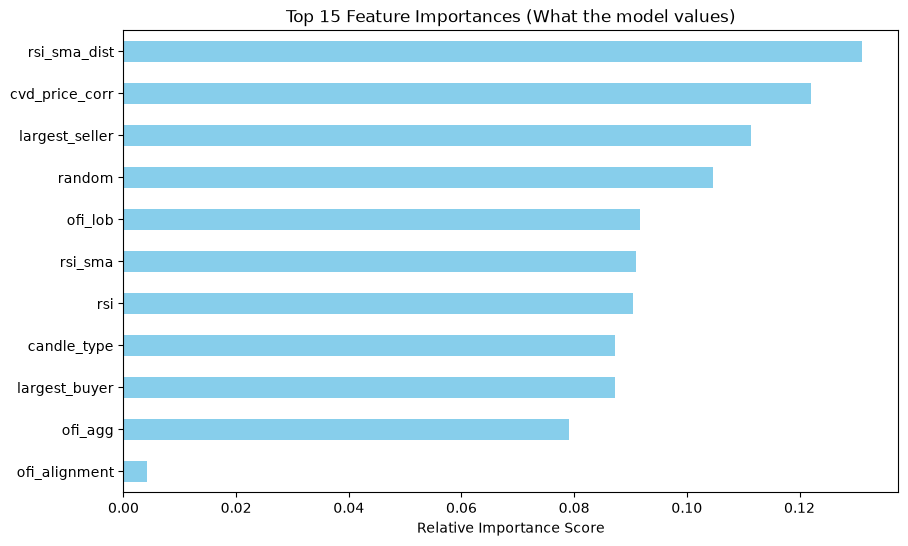

ofi_alignment     0.086945
rsi_sma_dist      0.050439
largest_seller    0.048629
cvd_price_corr    0.033201
candle_type       0.028663
random            0.005885
rsi               0.002395
rsi_sma           0.000000
largest_buyer     0.000000
ofi_agg           0.000000
ofi_lob           0.000000
dtype: float64
H(Y)                          = 1.5254 bits
I(X_5;    Y)                  = -0.2163 bits  (-14.2% of H(Y))
I(X_full [11 feats]; Y)  = -0.2362 bits  (-15.5% of H(Y))
Net gain from added features  = -0.0199 bits (-1.3% of H(Y))


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4 · Evaluate
# ─────────────────────────────────────────────────────────────────────────────
present_classes = sorted(np.unique(np.concatenate([y_tr, y_te])))
present_names   = [CLASS_NAMES[c] for c in present_classes]

y_pred = clf.predict(X_te_s)
proba  = clf.predict_proba(X_te_s)

print("\n── Classification Report ─────────────────────────────────────────")
print(classification_report(y_te, y_pred,
                             labels      = present_classes,
                             target_names= present_names))

cm = confusion_matrix(y_te, y_pred, labels=present_classes)
print("── Confusion Matrix ──────────────────────────────────────────────")
print(pd.DataFrame(cm,
      index   = [f"True  {n}" for n in present_names],
      columns = [f"Pred  {n}" for n in present_names]))

tscv  = TimeSeriesSplit(n_splits=5)
cv_f1 = []
for tr_idx, val_idx in tscv.split(X_tr_s):
    sw_f = compute_sample_weight('balanced', y_tr[tr_idx])
    m = GradientBoostingClassifier(n_estimators=100, max_depth=3,
            learning_rate=0.05, subsample=0.8, min_samples_leaf=5, random_state=42)
    m.fit(X_tr_s[tr_idx], y_tr[tr_idx], sample_weight=sw_f)
    cv_f1.append(f1_score(y_tr[val_idx], m.predict(X_tr_s[val_idx]),
                          labels=present_classes, average='macro'))

print(f"\nWalk-forward macro-F1: {np.mean(cv_f1):.3f} ± {np.std(cv_f1):.3f}")

import matplotlib.pyplot as plt

# 1. Create a Series of importances
feature_importances = pd.Series(clf.feature_importances_, index=FEATS)

# 2. Sort them and take the top 15
top_15 = feature_importances.nlargest(15)

# 3. Plot
plt.figure(figsize=(10, 6))
top_15.plot(kind='barh', color='skyblue')
plt.title("Top 15 Feature Importances (What the model values)")
plt.xlabel("Relative Importance Score")
plt.gca().invert_yaxis() # Highest at the top
plt.show()

from sklearn.feature_selection import mutual_info_classif

# Drop the columns that aren't features
X = feat_df.drop(columns=['target', 'streak_dur'])
y = feat_df['target']

# Calculate MI scores
mi_scores = mutual_info_classif(X, y, discrete_features=False)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

print(mi_series)


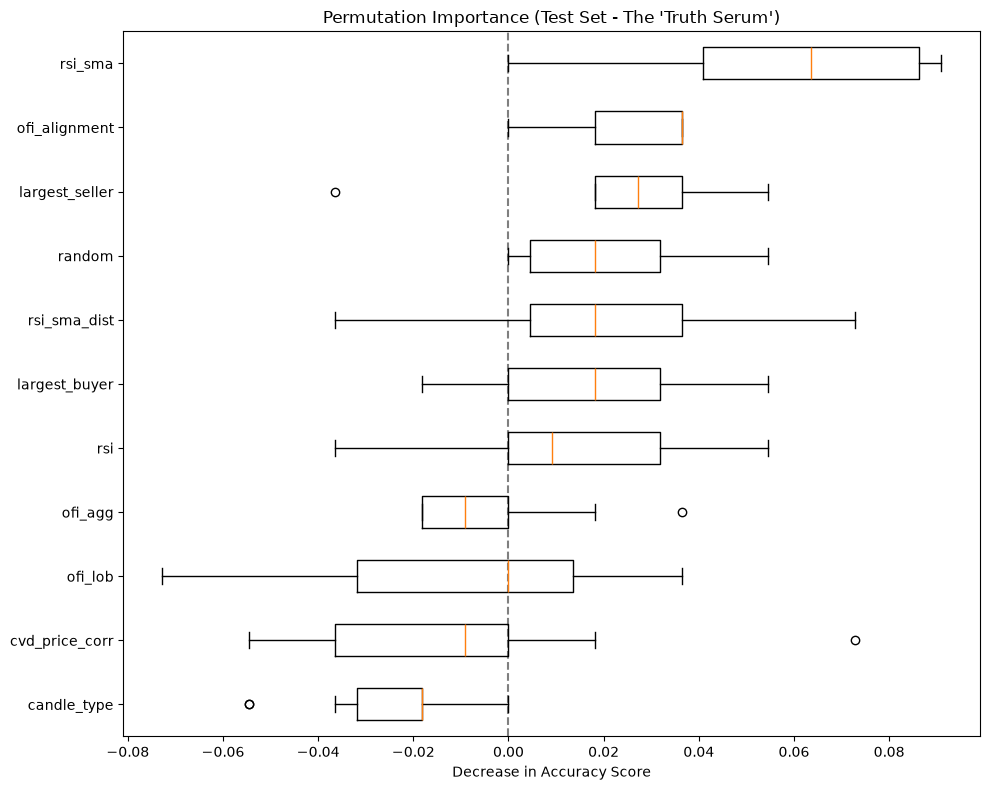

Features ranked by true predictive contribution:
rsi_sma: 0.0564
ofi_alignment: 0.0255
largest_seller: 0.0236
random: 0.0218
rsi_sma_dist: 0.0218
largest_buyer: 0.0145
rsi: 0.0127
ofi_agg: -0.0036
ofi_lob: -0.0109
cvd_price_corr: -0.0109
candle_type: -0.0255


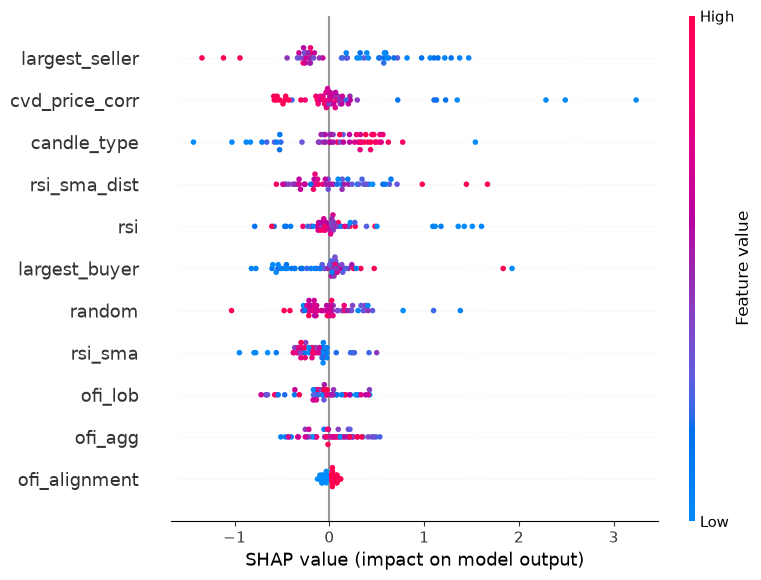

In [38]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# 1. Calculate Permutation Importance on the Test Set
# We use n_repeats=10 to get a stable estimate of the impact
result = permutation_importance(
    clf, X_te_s, y_te, 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

# 2. Prepare the data for plotting
perm_sorted_idx = result.importances_mean.argsort()
feature_names = np.array(FEATS)

# 3. Plotting
plt.figure(figsize=(10, 8))
plt.boxplot(
    result.importances[perm_sorted_idx].T,
    vert=False,
    tick_labels=feature_names[perm_sorted_idx]  # Use this instead of labels
)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.5)
plt.title("Permutation Importance (Test Set - The 'Truth Serum')")
plt.xlabel("Decrease in Accuracy Score")
plt.tight_layout()
plt.show()

# 4. Print the honest ranking
print("Features ranked by true predictive contribution:")
for i in perm_sorted_idx[::-1]:
    print(f"{feature_names[i]}: {result.importances_mean[i]:.4f}")

import shap

# Create a binary target for 'Medium' vs 'Not Medium'
y_tr_bin = (y_tr == 1).astype(int)

# Train a new binary model
binary_clf = GradientBoostingClassifier(n_estimators=100, max_depth=4).fit(X_tr_s, y_tr_bin)

# Now use the fast, reliable TreeExplainer
explainer = shap.TreeExplainer(binary_clf)
shap_values = explainer.shap_values(X_te_s)

# This will work perfectly without assertion errors
shap.summary_plot(shap_values, X_te_s, feature_names=FEATS)

# Conclusion
![Feature importance + Classification report](./image/img_5.png)
![Mutual Information](./image/img_6.png)

Model performs terribly and cannot be relied on. Majority of features underperform relative to random variable in the model.
- Price features doesn't seem to have any contribution to streak_duration, with the exception of RSI_SMA_DIST or RSI_SMA. This proves the theory that most price-based indicators have little to no predictive power. Volatility also failed to contribute to streak_duration where it has consistently underperformed relative to random variable. Possible reasoning for this is volatility ratio only contains information about magnitude of price movement but does not explain anything about the persistence of price movement. 
- Orderflow doesn't seem to have any contribution to streak_duration. Permutation Importance testing shows orderflow to be the largest contributor to decreasing accuracy score. At times, certain orderflow features such as OFI_alignment or largest_buyer/largest_seller could outperform RSI_SMA_DIST
    - OFI alignment should signify strong one sided movement which could contain information to persistence of a trend. However, due to the non-stationarity nature of the market, there is too much noise in orderflow to reliably predict persistence of a trend.
    - Largest buyer/seller could signify a large player entering the market aggressively, potentially becoming a leading signal to toxic, informed trading flow that the market has failed to priced in. However, it could also be market maker activity or other players that don't have any intent of trading intraday as large players often have execution algorithms to hide their transaction.
    - RSI-SMA-DIST has a directly effect to trend persistence where naturally, if RSI to SMA is very far apart from each other it is harder for price to break the trend. It does not hold any other information

## Why it failed
- Non-stationarity nature of market and noise makes predictions difficult to perform.
- Insufficient feature engineering, where the features used to train the model could be improved. For example, testing for widening of spread and depth of market to detect toxic informed trading flow over largest buyer/seller and OFI alignment. 
- Difficulty of problem. ML models specifically underperform on time-to-event problems. The possibility of 3-class classifier might've add complexity to the problem. 
- Small sample size, potential for overfitting, lack of predictive cues in data and model instability. Even with GBM classifier, sample size of 300 is too small. Using linear models might be more suitable over tree models. However nature of the data prediction might require conquer-and-divide method of GBM classifier to find complex rules.

## What Next?
Focus on approach_3 where we optimize for triple-barrier method or state-space modelling to avoid time-to-event problem. Meanwhile, collect more orderflow data and fix features, specifically in extracting information and eliminating noise of the market using context. Do not lapse out of approach_2 yet.